<a href="https://colab.research.google.com/github/oluakandes/Bike-share-case-study/blob/main/Case_Study_Cyclistic_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
print(pd.__version__)

2.2.3


In [ ]:
import glob

files = sorted(glob.glob("*.csv"))
print(len(files), "files found")
for f in files:
    print(f)

df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
print(df.shape)

12 files found
APRIL-3-2026-202603-divvy-tripdata.csv
AUG- 5- 2026-202607-divvy-tripdata.csv
DEC-8-2025-202511-divvy-tripdata.csv
FEB-4-2026-202601-divvy-tripdata 2.csv
JAN-5-2026-202512-divvy-tripdata.csv
JUL-6-2026-202606-divvy-tripdata.csv
JUNE-4-2026-202605-divvy-tripdata.csv
MARCH-4-2026-202602-divvy-tripdata.csv
MAY-4-2026-202604-divvy-tripdata.csv
NOV-5- 2026- 202610-divvy-tripdata.csv
OCT-5- 2026- 202609-divvy-tripdata.csv
SEPT-9- 2026- 202608-divvy-tripdata.csv
(6294451, 13)


In [ ]:
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6294451 entries, 0 to 6294450
Data columns (total 13 columns):
 #   Column              Dtype  
---  ------              -----  
 0   ride_id             object 
 1   rideable_type       object 
 2   started_at          object 
 3   ended_at            object 
 4   start_station_name  object 
 5   start_station_id    object 
 6   end_station_name    object 
 7   end_station_id      object 
 8   start_lat           float64
 9   start_lng           float64
 10  end_lat             float64
 11  end_lng             float64
 12  member_casual       object 
dtypes: float64(4), object(9)
memory usage: 624.3+ MB


,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,AE72B07EAC06D106,classic_bike,2026-03-20 09:07:13.866,2026-03-20 09:11:33.295,Chicago Ave & Sheridan Rd,CHI02043,Sheridan Rd & Noyes St (NU),CHI01114,42.050491,-87.677821,42.058239,-87.677432,member
1,2FC08B198BA431AA,classic_bike,2026-03-31 13:35:55.605,2026-03-31 13:39:31.356,Morgan St & Polk St,CHI00372,Loomis St & Lexington St,CHI00238,41.871737,-87.651030,41.872229,-87.661364,member
2,9360F18B10C847D9,electric_bike,2026-03-19 16:40:45.321,2026-03-19 16:43:28.905,Morgan St & Polk St,CHI00372,Loomis St & Lexington St,CHI00238,41.871737,-87.651030,41.872229,-87.661364,member
3,946494EB892374E9,classic_bike,2026-03-09 14:15:57.612,2026-03-09 14:21:38.563,Damen Ave & Pierce Ave,CHI02057,Damen Ave & Charleston St,CHI00403,41.909358,-87.677758,41.920082,-87.677855,member
4,6EE0E2DA57702502,electric_bike,2026-03-17 08:26:04.840,2026-03-17 08:26:12.374,Sheffield Ave & Webster Ave,CHI00507,Sheffield Ave & Webster Ave,CHI00507,41.921540,-87.653818,41.921540,-87.653818,member


In [ ]:
print("Duplicate ride_ids:", df.duplicated(subset="ride_id").sum())
print(df["member_casual"].value_counts())
print(df["rideable_type"].value_counts())
print("Missing values per column:")
print(df.isnull().sum())

Duplicate ride_ids: 35
member_casual
member    4055038
casual    2239413
Name: count, dtype: int64
rideable_type
electric_bike    4535196
classic_bike     1759255
Name: count, dtype: int64
Missing values per column:
ride_id                     0
rideable_type               0
started_at                  0
ended_at                    0
start_station_name    1301806
start_station_id      1301806
end_station_name      1367998
end_station_id        1367998
start_lat                   0
start_lng                   0
end_lat                  5303
end_lng                  5303
member_casual               0
dtype: int64


In [ ]:
# 1. Remove duplicate ride_ids
df = df.drop_duplicates(subset="ride_id")

# 2. Convert dates
df["started_at"] = pd.to_datetime(df["started_at"], format="mixed")
df["ended_at"] = pd.to_datetime(df["ended_at"], format="mixed")

# 3. Check the date range
print(df["started_at"].min(), "to", df["started_at"].max())

# 4. Add new columns
df["ride_length_min"] = (df["ended_at"] - df["started_at"]).dt.total_seconds() / 60
df["day_of_week"] = df["started_at"].dt.day_name()
df["month"] = df["started_at"].dt.to_period("M")
df["hour"] = df["started_at"].dt.hour

# 5. Check ride lengths
print(df["ride_length_min"].describe())
print("Negative or zero:", (df["ride_length_min"] <= 0).sum())
print("Under 1 minute:", (df["ride_length_min"] < 1).sum())
print("Over 24 hours:", (df["ride_length_min"] > 1440).sum())

2025-10-31 01:24:38.549000 to 2026-10-31 23:59:45.105000
count    6.294416e+06
mean     1.506859e+01
std      4.991849e+01
min     -5.479480e+01
25%      5.304417e+00
50%      9.197608e+00
75%      1.602332e+01
max      1.559950e+03
Name: ride_length_min, dtype: float64
Negative or zero: 29
Under 1 minute: 159672
Over 24 hours: 5148


In [ ]:
# Keep a copy of the row count for your cleaning log
before = len(df)

# Remove bad rides: under 1 minute, over 24 hours, and anything negative
df_clean = df[(df["ride_length_min"] >= 1) & (df["ride_length_min"] <= 1440)].copy()

# Drop rides with no end coordinates
df_clean = df_clean.dropna(subset=["end_lat", "end_lng"])

# Drop the stray October 2025 rides so you have 12 clean months
df_clean = df_clean[df_clean["started_at"] >= "2025-11-01"]

print("Rows before:", before)
print("Rows after:", len(df_clean))
print("Removed:", before - len(df_clean))

# Order the weekdays properly for later charts
day_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
df_clean["day_of_week"] = pd.Categorical(df_clean["day_of_week"], categories=day_order, ordered=True)

# First comparison: member vs casual ride length
print(df_clean.groupby("member_casual")["ride_length_min"].agg(["count","mean","median","max"]))

Rows before: 6294416
Rows after: 6129169
Removed: 165247
                 count       mean     median          max
member_casual                                            
casual         2161671  17.972668  11.091400  1439.274933
member         3967498  12.114347   8.677792  1439.719683


member_casual  casual  member
day_of_week                  
Monday         249673  554880
Tuesday        252130  647004
Wednesday      249099  631454
Thursday       263309  613649
Friday         334076  579950
Saturday       463878  519191
Sunday         349506  421370


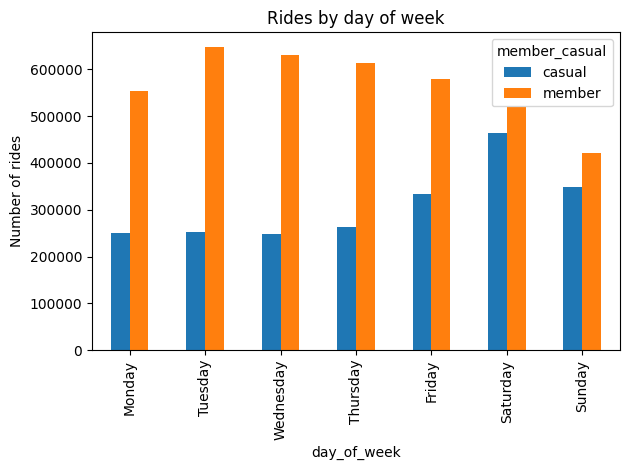

member_casual  casual  member
month                        
2025-11         94689  251912
2025-12         27087  109371
2026-01         23876  109855
2026-02         40072  157230
2026-03         84796  223643
2026-04        127006  308452
2026-05        235847  399508
2026-06        297204  444144
2026-07        345515  500453
2026-08        335478  511003
2026-09        284153  467091
2026-10        265948  484836


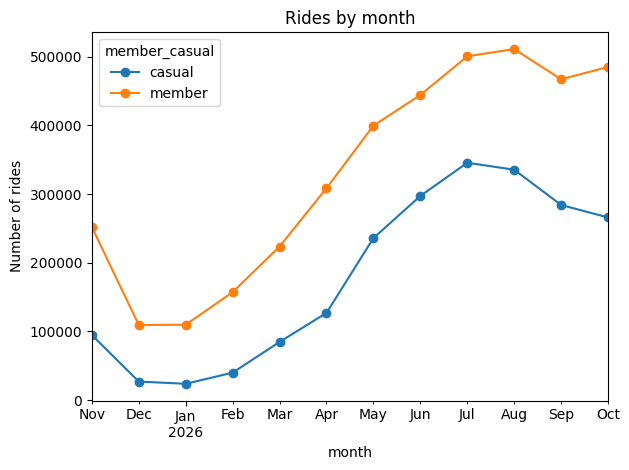

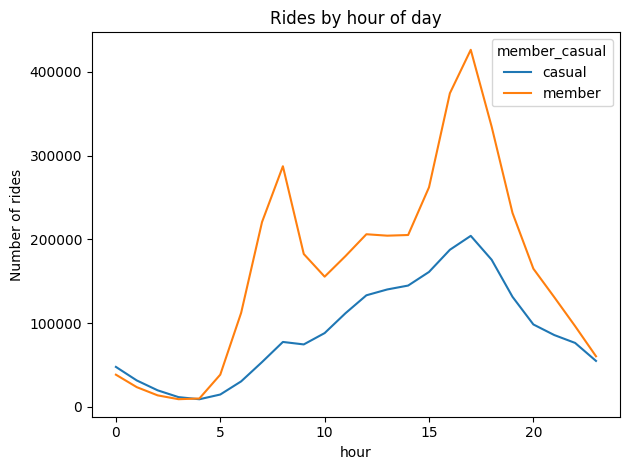

member_casual   casual   member
rideable_type                  
classic_bike    531775  1221939
electric_bike  1629896  2745559


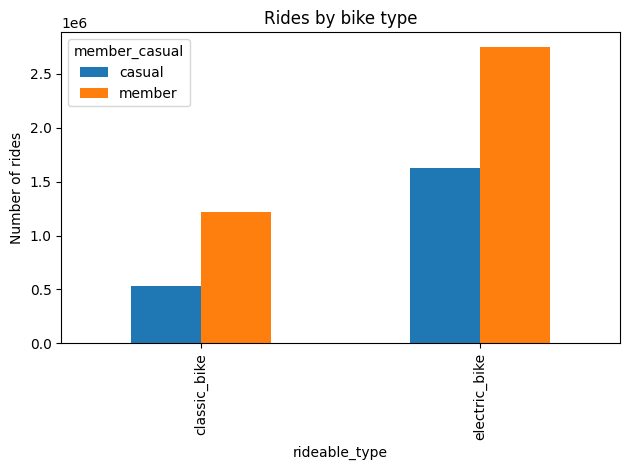

member_casual     casual     member
day_of_week                        
Monday         18.088602  11.804097
Tuesday        15.670923  11.711380
Wednesday      15.035522  11.595638
Thursday       15.711412  11.641012
Friday         17.568287  12.012892
Saturday       20.281026  13.357647
Sunday         20.670020  13.216002


In [ ]:
import matplotlib.pyplot as plt

# 1. Rides by day of week
by_day = df_clean.groupby(["day_of_week","member_casual"], observed=True).size().unstack()
print(by_day)
by_day.plot(kind="bar", title="Rides by day of week")
plt.ylabel("Number of rides"); plt.tight_layout(); plt.show()

# 2. Rides by month
by_month = df_clean.groupby(["month","member_casual"]).size().unstack()
print(by_month)
by_month.plot(kind="line", marker="o", title="Rides by month")
plt.ylabel("Number of rides"); plt.tight_layout(); plt.show()

# 3. Rides by hour
by_hour = df_clean.groupby(["hour","member_casual"]).size().unstack()
by_hour.plot(kind="line", title="Rides by hour of day")
plt.ylabel("Number of rides"); plt.tight_layout(); plt.show()

# 4. Bike type
by_bike = df_clean.groupby(["rideable_type","member_casual"]).size().unstack()
print(by_bike)
by_bike.plot(kind="bar", title="Rides by bike type")
plt.ylabel("Number of rides"); plt.tight_layout(); plt.show()

# 5. Average ride length by day
print(df_clean.groupby(["day_of_week","member_casual"], observed=True)["ride_length_min"].mean().unstack())

Cyclistic Bike-Share Analysis: Casual Riders vs Annual Members
Nov 23, 2026 · **@Olubunmi Akande**

**SUMMARY**
Annual members ride for routine trips and casual riders ride for leisure, so the best route to more members is a seasonal or weekend offer aimed at casual riders.

**•Size:** 6,129,169 cleaned rides, Nov 2025 to Oct 2026. Members made 65% of rides (3,967,498) and casual riders 35% (2,161,671).

**•Trip length:** casual trips average 18.0 minutes against 12.1 for members.

**•Timing:** members peak at about 8am and 5pm on weekdays; casual riders peak on Saturdays and in summer.

**•Seasonality:** casual rides rise 14.5 times from their lowest month to their highest, members only 4.7 times.

**1. ASK**
Business question: how do annual members and casual riders use Cyclistic bikes differently, and what does that tell us about turning casual riders into members? Cyclistic's finance team found that annual members are more profitable than casual riders. Converting existing casual riders is therefore a faster, cheaper route to growth than finding new customers.

**Sub-questions**
•When do each group ride (month, weekday, hour)?
•How long are their trips?
•Which bike types do they use?
•What would make a casual rider want a membership?

**Stakeholders:** the marketing director and the executive team. Success looks like clear, data-backed recommendations for a marketing strategy.

**2. PREPARE**
The analysis uses 12 monthly Divvy trip files (Chicago bike-share, the Cyclistic case-study data) covering Nov 2025 to Oct 2026. Combined, they hold 6,294,451 rides in 13 columns.

**Columns used:** ride_id, rideable_type, started_at, ended_at, start and end station name and ID, start and end latitude and longitude, member_casual.

**Tools:** Python (pandas and matplotlib) in Google Colab, because BigQuery was not available and the files are too large for a spreadsheet.
Data credibility (ROCCC).

**•Reliable and original:** first-party trip records published by the operator.

**•Comprehensive:** every ride is logged, but there is no rider ID, pricing or cost data.

**•Current:** the latest 12 months at the time of analysis.

**•Cited:** Divvy trip data, published under licence by the operator.
Missing values: about 1.3 million rides (21%) have no start station and 1.37 million have no end station, mostly electric bikes left outside stations. Another 5,303 rides have no end coordinates. Dates, ride IDs, bike type and rider type are complete.

3. **PROCESS**
Cleaning removed 165,282 of 6,294,451 rides (2.6%), leaving 6,129,169 rides for analysis.

**Steps**
1.Combined the 12 monthly files into one table.
2.Removed 35 duplicate ride IDs.
3.Converted start and end times from text to dates.
4.Added ride length (minutes), day of week, month and hour of day.
5.Removed rides that were too short, too long, invalid or outside the 12 months.

Cleaning log
Check	Rides affected	Action
Duplicate ride IDs	35	Removed
Zero or negative ride length (end before start)	29	Removed
Under 1 minute (includes the 29 above)	159,672	Removed as false starts
Over 24 hours	5,148	Removed as unreturned bikes
No end coordinates	5,303	Removed
Started before 1 Nov 2025	a few late-October rides	Removed to keep 12 full months
The counts overlap, so they do not add up to the total removed. After cleaning, the median ride is under 12 minutes for both groups.

4. **ANALYZE**
Members ride in a commuter pattern and casual riders in a leisure pattern, and casual riders take longer trips.

**Who rides, and for how long**
Rider type	Rides	Share of rides	Average ride (min)	Median ride (min)
Casual	2,161,671	35%	18.0	11.1
Member	3,967,498	65%	12.1	8.7
Day of week

Colab analysis of Divvy trip data · 6,129,169 cleaned rides, Nov 2025 to Oct 2026 Casual volume almost doubles from midweek to Saturday, while member volume falls from its Tuesday high of 647,004 rides to 421,370 on Sunday.

**Month**
Colab analysis of Divvy trip data · 6,129,169 cleaned rides, Nov 2025 to Oct 2026
Both groups peak in July and August and dip in December and January, but casual riding swings far more: 345,515 rides in July against 23,876 in January.

**Time of day**
Members have two clear peaks, at about 8am and 5pm, which is the commuting pattern. Casual riders build steadily through the day to a single peak at about 5pm, with no sharp morning rush. These hourly readings come from the Colab chart and are approximate.
Ride length

Colab analysis of Divvy trip data · 6,129,169 cleaned rides, Nov 2025 to Oct 2026 Member trips barely change across the week, while casual trips lengthen at weekends.

**Bike type**
Rider type	Classic bike rides	Electric bike rides	Electric share
Casual	531,775	1,629,896	75%
Member	1,221,939	2,745,559	69%

**5. SHARE**
***Audience:*** Cyclistic executive team

***Key message:*** Casual riders use Cyclistic bikes like leisure users, while annual members ride like commuters.

***Key findings***
1.Members ride like commuters. Their rides peak Tuesday to Thursday (about 610,000 to 650,000 rides per weekday over the year) and cluster around 8am and 5pm. Their average trip stays short and steady, at 11.6 to 13.4 minutes.

2.Casual riders ride like leisure users. Saturday is their busiest day (463,878 rides). Their trips are longest at weekends (about 20 minutes on average) and show no sharp morning peak.

3.Casual riders are a large but seasonal audience.* They make up 35% of all rides, but their monthly volume swings from 23,876 in January to 345,515 in July. Member volume never falls below 109,371 a month.

4.Bike type does not separate the groups.* Electric bikes dominate both, at 75% of casual rides and 69% of member rides (confirm this figure), so the difference lies in when and why people ride, not in what they ride.

***How the findings will be shared***

***Format:*** a slide deck (PowerPoint or Google Slides) built for executives, with one slide per finding and a closing summary.

***Visuals:*** one chart per finding, each comparing members and casual riders:
1.Rides by weekday
2.Rides by hour of day
3.Monthly rides
4.Average ride length by weekday
5.Bike type share
6.Yearly profit of Members Riders Vs Casual Riders

***Design:*** contrast, size and colour draw attention to the key insight on each slide, such as highlighting casual riders in a bold colour and members in a muted one. Each chart has an insight-led headline, a subtitle and clear labels.

***Accessibility:*** a colour-blind-safe palette, direct labels instead of relying on a legend, alt text on charts, and high contrast with readable font sizes.

***Deliverable:*** supporting visualizations and key findings.

6.** ACT**
Focus marketing on casual riders at weekends and in summer, and offer a membership shaped around how they ride.

**#	Recommendation	Evidence**
1	Run membership promotions on Saturdays and from May to September	Casual rides peak on Saturday and in June to August.

2	Offer a seasonal or weekend membership as a first step	Casual riding drops from 345,515 rides in July to 23,876 in January, so a full year may not appeal.

3	Show the saving from membership to riders with longer trips	Casual trips average 18.0 minutes against 12.1 for members.

4	Feature electric bikes in campaigns and member perks	75% of casual rides use electric bikes.

5	Offer weekday incentives to casual riders	Weekday casual use is low (about 250,000 rides on each of Monday to Wednesday over the year), while members commute.

**How to measure success: **track the share of casual riders who become members after each campaign, and compare weekend and summer sign-ups with the same months a year earlier.

**Limitations and next steps**
The findings show how the two groups ride, not why, and four gaps limit how far they can be pushed.

•No rider ID: we cannot tell how many different people casual riders are, or how often each one rides.

•No pricing or cost data: the extra profit from converting a casual rider cannot be estimated.

**•Missing stations:** 21% of rides have no start station, so station-level analysis covers only part of the data.

**•One year only:** a single 12-month window may not represent longer trends.

**Next steps:** add pricing data, survey casual riders on what would make them join, and repeat the analysis for the next 12 months.